---

# 🔧 Appendix: Generalized Shor's Algorithm

This section implements Shor's algorithm in a **fully parametric** way, so that any pair $(a, N)$ with $\gcd(a, N) = 1$ can be chosen.

## The Problem with the Standard Implementation

In the main notebook the function `c_amod15` is **hardcoded** for N=15. To generalize, we must implement the operation

$$|x\rangle \mapsto |a \cdot x \mod N\rangle$$

in a general way.

## Possible Approaches

1. **Permutation Matrix**: builds the unitary operator explicitly. Simple, but limited to small N (~64-128).

2. **Arithmetic Circuits**: uses modular adders (Draper, VBE). Scales better, but the circuits are very deep.

3. **Hybrid Approach**: combines a classical simulation of the oracle with quantum QPE.

## Method 1: Permutation Matrix

The operation $|x\rangle \mapsto |a \cdot x \mod N\rangle$ is a **permutation** of the basis states. We can build the unitary matrix explicitly.

In [1]:
# Required imports
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister   # circuits and their named qubit / bit registers
from qiskit_aer import AerSimulator                     # local classical simulator of a quantum computer
from qiskit_aer.primitives import SamplerV2             # the Qiskit 2.x "primitive" that runs circuits and returns per-register counts
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager   # transpiler: circuit -> the backend's gate set
from qiskit.circuit.library import UnitaryGate          # a gate defined by an explicit matrix (here: a permutation matrix)
from qiskit.visualization import plot_histogram         # bar chart of measurement counts
import numpy as np                                      # matrices, np.argmax, np.pi
from math import gcd, ceil, log2                        # greatest common divisor; ceil(log2(N)) = number of bits of N
from fractions import Fraction                          # exact rationals; .limit_denominator() = continued fractions in one call
from typing import Tuple, List, Optional                # type hints only (documentation; Python does not check them)
from IPython.display import display                      # show a figure (e.g. a circuit drawing) from the middle of a cell
def draw(qc, fold=-1, **kw): return qc.draw("mpl", style="clifford", fold=fold, **kw)   # every circuit picture: matplotlib drawer; fold=-1 = one long row, fold=N wraps after N columns

import qiskit; print(f"✓ Imports for generalized Shor (Qiskit {qiskit.__version__})")


✓ Imports for generalized Shor (Qiskit 2.1.2)


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `UnitaryGate` | turns any unitary matrix into a gate; the transpiler must then *synthesise* it into elementary gates — the price of this general method (see Section Limitations) |
| `AerSimulator`, `SamplerV2`, `generate_preset_pass_manager` | the execution stack of the IBM edition: simulator, the primitive that samples it, the transpiler that rewrites our gates for it |
| `from typing import Tuple, List, Optional` | annotations such as `-> Optional[int]` document that a function returns an int or None; they have no effect at run time |
| `draw(qc)` | our one-line helper around `qc.draw("mpl", style="clifford", fold=...)`; `display()` shows a figure that is not the last line of a cell |

</details>


In [2]:
def modular_multiplication_matrix(a: int, N: int) -> np.ndarray:
    """
    Build the permutation matrix of the modular multiplication.
    
    The operation is: |x⟩ → |a·x mod N⟩ for x < N
                      |x⟩ → |x⟩        for x >= N (unused states)
    
    Args:
        a: Multiplier (must be coprime with N)
        N: Modulus
    
    Returns:
        Unitary matrix of size 2^n × 2^n, where n = ceil(log2(N))
    """
    if gcd(a, N) != 1:
        raise ValueError(f"a={a} must be coprime with N={N}")   # raise = abort with an error message; without gcd = 1 the map is not a bijection
    
    # Number of qubits needed
    n_qubits = ceil(log2(N + 1))  # +1 for safety                # enough qubits to hold 0 … N (N = 15 -> 4, 21 -> 5, 35 -> 6)
    dim = 2 ** n_qubits
    
    # Build the permutation matrix
    U = np.zeros((dim, dim), dtype=complex)                      # dim × dim complex zeros; one 1 per column will make it a permutation
    
    for x in range(dim):
        if x < N:
            # Multiply mod N
            y = (a * x) % N
        else:
            # Out-of-range states: identity
            y = x                                                # the basis states ≥ N are never reached: map them to themselves
        U[y, x] = 1.0                                            # column x has its single 1 in row y: U|x⟩ = |y⟩
    
    return U


def create_controlled_modmul_gate(a: int, power: int, N: int) -> UnitaryGate:
    """
    Create the controlled gate for a^(2^power) mod N.
    
    Args:
        a: Base
        power: Exponent (the gate computes a^(2^power) mod N)
        N: Modulus
    
    Returns:
        Controlled UnitaryGate
    """
    # Compute a^(2^power) mod N
    a_power = pow(a, 2**power, N)                                # classical modular exponentiation: ONE multiplication by a^(2^power) mod N, never 2^power repetitions of U
    
    # Build the matrix
    U_matrix = modular_multiplication_matrix(a_power, N)
    
    # Create the gate
    gate = UnitaryGate(U_matrix, label=f'{a}^{2**power} mod {N}')   # a gate from a matrix; the label is what the drawings show
    
    return gate.control(1, label=f'c-{a}^{2**power}')            # add 1 control qubit: a (2·dim) × (2·dim) controlled unitary


# Test
print("Test: matrix for 7·x mod 15")
U = modular_multiplication_matrix(7, 15)
print(f"Matrix size: {U.shape}")
print(f"Is unitary: {np.allclose(U @ U.conj().T, np.eye(16))}")   # @ = matrix product; U U† = I is the definition of unitary

# Check a few multiplications
print("\nCheck:")
for x in range(5):
    # Find where |x⟩ goes
    y = np.argmax(U[:, x])                                       # the row of the 1 in column x
    expected = (7 * x) % 15
    print(f"  |{x}⟩ → |{y}⟩  (expected: {expected}) {'✓' if y == expected else '✗'}")
print("Full permutation x → 7x mod 15:", list(np.argmax(U, axis=0)))   # the row of the 1 in every column; 0, 5, 10 and 15 are fixed points


Test: matrix for 7·x mod 15
Matrix size: (16, 16)
Is unitary: True

Check:
  |0⟩ → |0⟩  (expected: 0) ✓
  |1⟩ → |7⟩  (expected: 7) ✓
  |2⟩ → |14⟩  (expected: 14) ✓
  |3⟩ → |6⟩  (expected: 6) ✓
  |4⟩ → |13⟩  (expected: 13) ✓
Full permutation x → 7x mod 15: [np.int64(0), np.int64(7), np.int64(14), np.int64(6), np.int64(13), np.int64(5), np.int64(12), np.int64(4), np.int64(11), np.int64(3), np.int64(10), np.int64(2), np.int64(9), np.int64(1), np.int64(8), np.int64(15)]


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `np.zeros((dim, dim), dtype=complex)`; `U[y, x] = 1.0` | a permutation matrix: exactly one 1 per column (and per row, because gcd(a, N) = 1 makes x → ax mod N a bijection); column x says where \|x⟩ goes |
| `y = x` for `x >= N` | the 2ⁿ − N unused basis states are fixed points, so the matrix stays a permutation (hence unitary) on the whole 2ⁿ-dimensional space |
| `pow(a, 2**power, N)` | the classical shortcut of Shor's algorithm: a^(2^k) mod N is computed first, and the gate multiplies by that number once (notebook 20's textbook version repeats U instead) |
| `UnitaryGate(matrix, label=...)`, `.control(1, label=...)` | a gate from an explicit matrix and its controlled version; the transpiler will have to synthesise them into elementary gates — expensive for a generic 2ⁿ × 2ⁿ matrix |
| `np.allclose(U @ U.conj().T, np.eye(16))` | the unitarity check U U† = I with a numerical tolerance; `np.argmax(U[:, x])` reads the image of x off the matrix |

</details>


<details open><summary><b>📐 Working it out</b></summary>

**The permutation matrix of ×7 mod 15 — where the 1s go.** $n = \lceil\log_2 16\rceil = 4$ qubits, a $16 \times 16$ matrix with $U_{y,x} = 1$ exactly when $y = 7x \bmod 15$ (and $y = x$ for $x = 15$). Column by column:

$$x:\ 0\ 1\ 2\ 3\ 4\ 5\ 6\ 7\ 8\ 9\ 10\ 11\ 12\ 13\ 14\ 15 \quad\longrightarrow\quad y:\ 0\ 7\ 14\ 6\ 13\ 5\ 12\ 4\ 11\ 3\ 10\ 2\ 9\ 1\ 8\ 15$$

e.g. $7\cdot 2 = 14$, $7\cdot 3 = 21 = 15 + 6$, $7\cdot 4 = 28 = 15 + 13$, $7\cdot 5 = 35 = 2\cdot 15 + 5$. The cell prints the first five images, $0, 7, 14, 6, 13$ ✓, and the full list.

*Four diagonal 1s.* $x = 0, 5, 10$ are fixed ($7x \equiv x$ because $6x \equiv 0$, i.e. $x$ a multiple of 5) and so is the unused $x = 15$. Note the difference from the swap construction of notebook 20, which interchanges $0 \leftrightarrow 15$: both are legitimate, because the algorithm never visits those states.

*Why unitary.* Every column is a standard basis vector and no two columns coincide (the map is a bijection since $\gcd(7, 15) = 1$), so the columns are orthonormal and $U U^\dagger = I$ — the `True` printed by the cell. Its inverse is the matrix of $\times 7^{-1} = \times 13$.

*Cycles = the order.* Following the arrows: $1 \to 7 \to 4 \to 13 \to 1$, $\;2 \to 14 \to 8 \to 11 \to 2$, $\;3 \to 6 \to 12 \to 9 \to 3$: three 4-cycles and four fixed points. The eigenvalues of a permutation matrix are the $L$-th roots of unity of its $L$-cycles, so here they are $e^{2\pi i s/4}$ — the phases $s/r$ that QPE measures (In-depth task 1 checks this numerically for $N = 21$ and $35$).

</details>


## Generalized QPE Implementation for Shor

Shor circuit configuration:
  N = 15, a = 7
  Counting qubits: 8
  Target qubits: 4
  Total qubits: 12



Circuit built:
  Depth: 26
  Total gates: 65


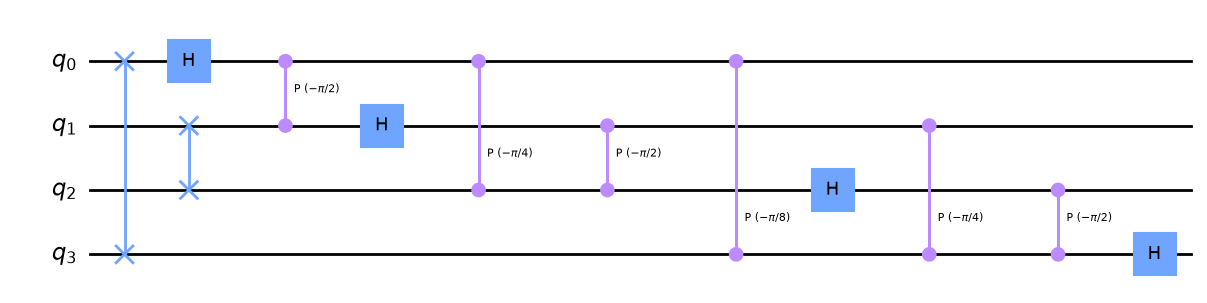

↑ inverse_qft(4): the swaps reverse the qubit order, then Hadamards interleaved with controlled phases of −π/2, −π/4, −π/8 — the same QFT† as QFTGate(4).inverse() in notebook 20


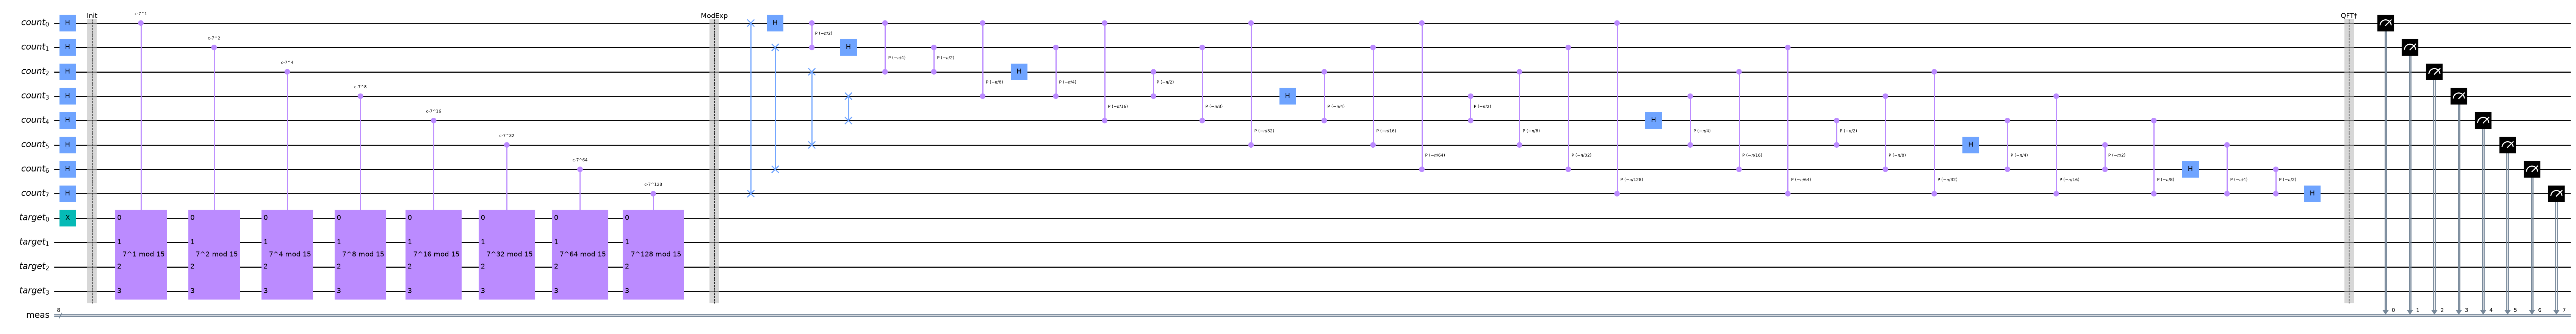

↑ the general circuit for a = 7, N = 15: 8 counting qubits, a 4-qubit target register, one controlled UnitaryGate per counting qubit (labelled with the power it multiplies by), QFT† written out gate by gate, then the measurements


In [3]:
def inverse_qft(n: int) -> QuantumCircuit:
    """Inverse QFT on n qubits."""
    qc = QuantumCircuit(n, name='QFT†')
    
    for i in range(n // 2):                          # the swaps come FIRST in QFT†: they undo the bit reversal that the QFT leaves at its end
        qc.swap(i, n - i - 1)
    
    for j in range(n):
        for k in range(j):
            qc.cp(-np.pi / (2 ** (j - k)), k, j)     # qc.cp(theta, control, target): controlled phase −π/2^(j−k)
        qc.h(j)                                      # Hadamard on qubit j after its controlled phases

    return qc


def build_shor_circuit_general(a: int, N: int, n_count: int = None) -> QuantumCircuit:
    """
    Build the generalized Shor circuit for any coprime (a, N).
    
    Args:
        a: Base of the modular exponentiation
        N: Number to factor
        n_count: Counting qubits (default: 2*ceil(log2(N)))
    
    Returns:
        Quantum circuit that finds the period of a^x mod N
    """
    # Validation
    if gcd(a, N) != 1:
        raise ValueError(f"a={a} and N={N} must be coprime")
    
    if a >= N:
        raise ValueError(f"a={a} must be smaller than N={N}")
    
    # Compute the qubits needed
    n_target = ceil(log2(N + 1))  # Qubits for the target register   # must hold the numbers 0 … N−1
    if n_count is None:
        n_count = 2 * n_target  # Standard precision               # 2^n_count ≥ N²: the continued-fraction guarantee
    
    print(f"Shor circuit configuration:")
    print(f"  N = {N}, a = {a}")
    print(f"  Counting qubits: {n_count}")
    print(f"  Target qubits: {n_target}")
    print(f"  Total qubits: {n_count + n_target}")
    
    # Registers
    count_reg = QuantumRegister(n_count, 'count')                    # named registers: the drawing shows count_0 …, target_0 …
    target_reg = QuantumRegister(n_target, 'target')
    meas_reg = ClassicalRegister(n_count, 'meas')
    
    qc = QuantumCircuit(count_reg, target_reg, meas_reg)
    
    # ═══════════════════════════════════════════════════════════════
    # STEP 1: Initialisation
    # - Counting register in a uniform superposition
    # - Target register in |1⟩ (because a^0 = 1)
    # ═══════════════════════════════════════════════════════════════
    qc.h(count_reg)                                                  # a gate on a whole register = on each of its qubits
    qc.x(target_reg[0])  # |1⟩ = |00...01⟩                           # register[0] = its least significant qubit
    
    qc.barrier(label='Init')                                         # labelled barrier: only a separator in the drawing
    
    # ═══════════════════════════════════════════════════════════════
    # STEP 2: Controlled modular exponentiation
    # |j⟩|1⟩ → |j⟩|a^j mod N⟩
    # 
    # Using the decomposition: a^j = a^(j₀·2⁰) · a^(j₁·2¹) · ... 
    # ═══════════════════════════════════════════════════════════════
    for k in range(n_count):
        # Create the controlled gate for a^(2^k) mod N
        c_gate = create_controlled_modmul_gate(a, k, N)
        
        # Apply: the control qubit is count[k], the target is the whole target register
        qc.append(c_gate, [count_reg[k]] + list(target_reg))        # append(gate, qubits): control first, then the target register
    
    qc.barrier(label='ModExp')
    
    # ═══════════════════════════════════════════════════════════════
    # STEP 3: Inverse QFT on the counting register
    # ═══════════════════════════════════════════════════════════════
    qft_inv = inverse_qft(n_count)
    qc.compose(qft_inv, count_reg, inplace=True)                     # compose: paste a circuit onto the given qubits (inplace: modify qc)
    
    qc.barrier(label='QFT†')
    
    # ═══════════════════════════════════════════════════════════════
    # STEP 4: Measurement
    # ═══════════════════════════════════════════════════════════════
    qc.measure(count_reg, meas_reg)                                  # count_k -> meas_k; the target register is not measured
    
    return qc


# Test: Shor for a=7, N=15
print("="*60)
qc_test = build_shor_circuit_general(a=7, N=15, n_count=8)
print(f"\nCircuit built:")
print(f"  Depth: {qc_test.depth()}")
print(f"  Total gates: {qc_test.size()}")

display(draw(inverse_qft(4))); print("↑ inverse_qft(4): the swaps reverse the qubit order, then Hadamards interleaved with controlled phases of −π/2, −π/4, −π/8 — the same QFT† as QFTGate(4).inverse() in notebook 20")
display(draw(qc_test)); print("↑ the general circuit for a = 7, N = 15: 8 counting qubits, a 4-qubit target register, one controlled UnitaryGate per counting qubit (labelled with the power it multiplies by), QFT† written out gate by gate, then the measurements")


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `inverse_qft(n)`: swaps, then `cp(−π/2^(j−k), k, j)` and `h(j)` | the standard QFT† (identical to `QFTGate(n).inverse()`): the swaps must come *before* the rotations — the original version had them after, which is a different unitary (its peaks appeared at m = 127, 255 instead of 64, 192) |
| `n_target = ceil(log2(N + 1))`, `n_count = 2 * n_target` | enough target qubits for 0 … N and twice as many counting qubits, so that 2^n_count ≥ N² and the continued fractions are guaranteed to work |
| `qc.h(count_reg)`, `qc.x(target_reg[0])` | uniform superposition on the counting register; \|1⟩ on the target register = an equal superposition of all eigenstates \|u_s⟩ of U |
| `qc.append(c_gate, [count_reg[k]] + list(target_reg))` | controlled-U^(2^k) with count_k as control: the QPE pattern, one 2^(n_target+1)-dimensional unitary per counting qubit |
| `qc.compose(qft_inv, count_reg, inplace=True)` | paste the QFT† circuit onto the counting qubits (as gates, not as a box: that is why the drawing shows it expanded) |
| `qc_test.size()` | at this level each controlled unitary is one instruction; after transpilation each becomes thousands of gates (printed by `run_shor_general`) |

</details>


## Analysis and Post-Processing Functions

In [4]:
def extract_period_from_phase(phase: float, N: int) -> Optional[int]:
    """
    Extract the period from the measured phase using continued fractions.
    
    Args:
        phase: Measured phase (s/2^n)
        N: Modulus (upper bound for the period)
    
    Returns:
        Candidate period or None
    """
    if phase == 0:
        return None                                   # phase 0 (s = 0) says nothing about r
    
    # Use continued fractions to find s/r
    frac = Fraction(phase).limit_denominator(N)       # the closest fraction with denominator ≤ N: the continued-fraction convergent (notebook 20 codes this by hand)
    
    return frac.denominator                           # the candidate r (s = frac.numerator is not needed)


def find_factors(a: int, r: int, N: int) -> Tuple[Optional[int], Optional[int]]:
    """
    Find the factors of N given the period r.
    
    If r is even and a^(r/2) ≠ -1 (mod N), then:
    - gcd(a^(r/2) + 1, N) is a factor
    - gcd(a^(r/2) - 1, N) is a factor
    
    Args:
        a: Base used
        r: Period found
        N: Number to factor
    
    Returns:
        (factor1, factor2), or (None, None) on failure
    """
    # Check that r really is the period
    if pow(a, r, N) != 1:                             # the classical check: a divisor of r (e.g. r/2 when s is even) fails here
        return None, None
    
    # r must be even
    if r % 2 == 1:
        return None, None
    
    # Compute a^(r/2) mod N
    x = pow(a, r // 2, N)                             # a square root of 1 modulo N
    
    # a^(r/2) ≠ -1 (mod N)
    if x == N - 1:                                    # the trivial root −1: both gcds are trivial
        return None, None
    
    # Compute the factors
    f1 = gcd(x + 1, N)                                # N | (x − 1)(x + 1) but divides neither factor: the primes split between the two gcds
    f2 = gcd(x - 1, N)
    
    # Check that they are non-trivial factors
    if f1 == 1 or f1 == N:
        f1 = None
    if f2 == 1 or f2 == N:
        f2 = None
    
    return f1, f2


def analyze_shor_results(counts: dict, n_count: int, a: int, N: int) -> dict:
    """
    Analyse the results of Shor's algorithm.
    
    Args:
        counts: Measurement counts
        n_count: Number of counting qubits
        a: Base used
        N: Number to factor
    
    Returns:
        Dictionary with the periods, phases and factors found
    """
    total_shots = sum(counts.values())
    
    print("═" * 70)
    print(f"SHOR RESULTS ANALYSIS for a={a}, N={N}")
    print("═" * 70)
    
    # Compute the classical period, for checking
    r_true = 1
    temp = a
    while temp != 1:                                  # brute-force order, as in notebook 20's classical_period
        temp = (temp * a) % N
        r_true += 1
    print(f"\nTrue period (classical): r = {r_true}")
    
    # Analyse the measurements
    print(f"\n{'Outcome':<12} {'Decimal':<10} {'Phase':<12} {'Period':<10} {'Counts':<10}")   # {'text':<12} = left-aligned in 12 characters
    print("-" * 60)
    
    periods_found = {}
    sorted_counts = sorted(counts.items(), key=lambda x: -x[1])   # most frequent outcomes first
    
    for bitstring, count in sorted_counts[:12]:                   # only the 12 most frequent outcomes are analysed
        decimal = int(bitstring, 2)                               # bitstring -> integer m
        phase = decimal / (2 ** n_count)                          # φ = m / 2^n
        period = extract_period_from_phase(phase, N)
        
        if period and period > 0:
            if period not in periods_found:
                periods_found[period] = 0
            periods_found[period] += count                        # shots behind each candidate period
        
        period_str = str(period) if period else "-"
        print(f"{bitstring:<12} {decimal:<10} {phase:<12.4f} {period_str:<10} {count:<10}")
    
    # Summary of the periods
    print(f"\n{'─'*60}")
    print("Periods found (sorted by frequency):")
    for r, cnt in sorted(periods_found.items(), key=lambda x: -x[1])[:5]:
        is_true = "✓" if r == r_true else ""
        is_valid = "(valid)" if pow(a, r, N) == 1 else "(invalid)"   # valid = a^r ≡ 1 (the true order or a multiple of it)
        print(f"  r = {r}: {cnt} counts {is_valid} {is_true}")
    
    # Attempt the factorisation
    print(f"\n{'─'*60}")
    print("Factorisation attempts:")
    
    factors_found = None
    for r in sorted(periods_found.keys(), key=lambda x: -periods_found[x]):   # try the candidates, most frequent first
        f1, f2 = find_factors(a, r, N)
        if f1 or f2:                                              # at least one non-trivial factor
            factors_found = (f1, f2)
            print(f"  r = {r}: Factors found! {f1} × {f2 if f2 else N//f1} = {N}")
            break
        else:
            reason = ""
            if pow(a, r, N) != 1:
                reason = "(r is not a period)"
            elif r % 2 == 1:
                reason = "(r odd)"
            else:
                reason = "(a^(r/2) ≡ -1)"
            print(f"  r = {r}: Failed {reason}")
    
    if not factors_found:
        print("  ⚠ No factor found. Try another base a.")
    
    return {
        'periods': periods_found,
        'true_period': r_true,
        'factors': factors_found
    }


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `Fraction(phase).limit_denominator(N)` | continued fractions in one library call: the best rational approximation of φ with denominator ≤ N; its denominator is the candidate r (notebook 20 builds the convergents by hand and tests them one by one) |
| `pow(a, r, N) != 1` → `(None, None)` | a candidate that is only a divisor of the order (s and r not coprime, e.g. φ = 2/6 → 1/3 → r = 3 for N = 21) is rejected here; this version does not try multiples, so such shots are lost |
| `x == N - 1`, `gcd(x ± 1, N)` | the two classical conditions of Shor's theorem and the gcd step that splits N |
| `sorted_counts[:12]` | the analysis looks only at the 12 most frequent outcomes: fine on an ideal simulator, lossy on a noisy backend where the counts spread over hundreds of bitstrings |
| `f"{bitstring:<12} {phase:<12.4f}"` | format specifications: left-aligned in 12 characters, 4 decimals — a plain-text table |
| `(valid)` / `(invalid)`, `Factors found!` | a period is valid if aʳ ≡ 1; the first valid, even period with a^(r/2) ≢ −1 yields the factors |

</details>


## Complete Function: Generalized Shor

In [5]:
def run_shor_general(N: int, a: int = None, n_count: int = None, 
                     shots: int = 4096, verbose: bool = True) -> dict:
    """
    Run the complete Shor algorithm to factor N.
    
    Args:
        N: Number to factor (must be composite, not prime)
        a: Base of the exponentiation (if None, chosen automatically)
        n_count: Counting qubits (if None, uses 2*ceil(log2(N)))
        shots: Number of measurements
        verbose: Whether to print details
    
    Returns:
        Dictionary with the complete results
    """
    # ═══════════════════════════════════════════════════════════════
    # CLASSICAL PART 1: Validation and setup
    # ═══════════════════════════════════════════════════════════════
    
    # Check that N is not too large
    if N > 128:
        print(f"⚠ WARNING: N={N} may be too large.")
        print(f"  The permutation-matrix method requires 2^{ceil(log2(N))} elements.")
        print(f"  For large N, use the arithmetic-circuit method.")
    
    # Check that N is composite
    def is_prime(n):                                   # a function defined inside a function: trial division up to √n
        if n < 2: return False
        for i in range(2, int(n**0.5) + 1):
            if n % i == 0: return False
        return True
    
    if is_prime(N):
        print(f"N={N} is prime! It cannot be factored.")
        return None
    
    # Check whether N is a prime power
    for p in range(2, int(log2(N)) + 2):               # is N = root^p for some p ≥ 2? (Shor's algorithm needs at least two distinct primes)
        root = round(N ** (1/p))                       # floating-point p-th root, then an exact integer check
        if root ** p == N:
            print(f"N={N} = {root}^{p} (prime power)")
            return {'factors': (root, N // root), 'method': 'power_detection'}
    
    # ═══════════════════════════════════════════════════════════════
    # CLASSICAL PART 2: Choice of the base a
    # ═══════════════════════════════════════════════════════════════
    
    if a is None:
        # Choose a random a coprime with N
        import random
        candidates = [x for x in range(2, N) if gcd(x, N) == 1]   # list comprehension: all bases coprime to N
        a = random.choice(candidates)                  # a random element (no seed: every run may differ)
        if verbose:
            print(f"Base chosen automatically: a = {a}")
    
    # Check whether we found a factor by chance
    g = gcd(a, N)
    if g > 1:
        if verbose:
            print(f"Lucky! gcd({a}, {N}) = {g} is a factor!")
        return {'factors': (g, N // g), 'method': 'gcd_lucky'}
    
    # ═══════════════════════════════════════════════════════════════
    # QUANTUM PART: Period Finding
    # ═══════════════════════════════════════════════════════════════
    
    if verbose:
        print(f"\n{'═'*60}")
        print(f"GENERALIZED SHOR ALGORITHM")
        print(f"{'═'*60}")
        print(f"Goal: factor N = {N}")
        print(f"Base: a = {a}")
    
    # Build the circuit
    qc = build_shor_circuit_general(a, N, n_count)
    actual_n_count = qc.num_clbits                     # the counting qubits really used (n_count may have been None)
    if verbose:
        display(draw(qc)); print(f"↑ the circuit for a = {a}, N = {N}: {actual_n_count} counting + {qc.num_qubits - actual_n_count} target qubits, one controlled unitary per counting qubit, then QFT† and the measurements")
    # Run
    if verbose:
        print(f"\nRunning the simulation...")
    
    simulator = AerSimulator()                         # local ideal simulator
    sampler = SamplerV2()                              # the primitive that samples it
    pm = generate_preset_pass_manager(optimization_level=1, backend=simulator)
    transpiled = pm.run(qc)                            # here the generic unitaries are SYNTHESISED into CNOT + 1-qubit gates: the size explodes
    if verbose:
        print(f"transpiled for Aer: {transpiled.size()} gates, depth {transpiled.depth()}, {transpiled.count_ops().get('cx', 0)} CNOTs "
              f"(the swap-based multiplier of notebook 20 needs ≈ 3 400 gates for N = 15; IQM Resonance would refuse anything above 10 000 native instructions)")
    
    job = sampler.run([transpiled], shots=shots)       # a list of circuits; shots = repetitions
    result = job.result()
    counts = result[0].data.meas.get_counts()          # the counts of the classical register named 'meas': {bitstring: count}
    
    # ═══════════════════════════════════════════════════════════════
    # CLASSICAL PART 3: Analysis of the results
    # ═══════════════════════════════════════════════════════════════
    
    analysis = analyze_shor_results(counts, actual_n_count, a, N)
    
    return {
        'N': N,
        'a': a,
        'counts': counts,
        'analysis': analysis,
        'circuit': qc
    }


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `def is_prime(n)` inside `run_shor_general` | a nested helper: Shor's algorithm needs a composite N; a prime is rejected before any quantum work |
| `round(N ** (1/p)) ** p == N` | perfect powers (N = rᵖ) are the other classical exception: the order-finding trick cannot split them, so they are caught by a root test |
| `random.choice(candidates)` | a random base coprime to N when none is given (no seed: Example 4 can differ from run to run); `gcd(a, N) > 1` would already be a factor |
| `display(draw(qc))` inside the function | the drawing is produced by `display`, not by the cell's last expression — a figure returned from inside a function would otherwise be lost |
| `pm.run(qc)` and the printed size | the transpiler *synthesises* each controlled UnitaryGate into CNOT + 1-qubit gates: ≈ 1 300 gates for N = 15, ≈ 27 000 for N = 21, ≈ 134 000 for N = 35 — the quadratic-in-dimension cost of a generic unitary (≈ 4ⁿ CNOTs for n qubits) |
| `SamplerV2().run([transpiled], shots=shots)`, `result[0].data.meas.get_counts()` | run and read the counts of the classical register `meas`; Aer simulates even the 134 000-gate circuit in about a minute |
| `return {...}` | a dict with everything downstream cells need: `counts` for the histogram, `analysis['factors']` for `try_multiple_bases` |

</details>


## Usage Examples


▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓
EXAMPLE 1: N = 15, a = 7
▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓

════════════════════════════════════════════════════════════
GENERALIZED SHOR ALGORITHM
════════════════════════════════════════════════════════════
Goal: factor N = 15
Base: a = 7
Shor circuit configuration:
  N = 15, a = 7
  Counting qubits: 8
  Target qubits: 4
  Total qubits: 12


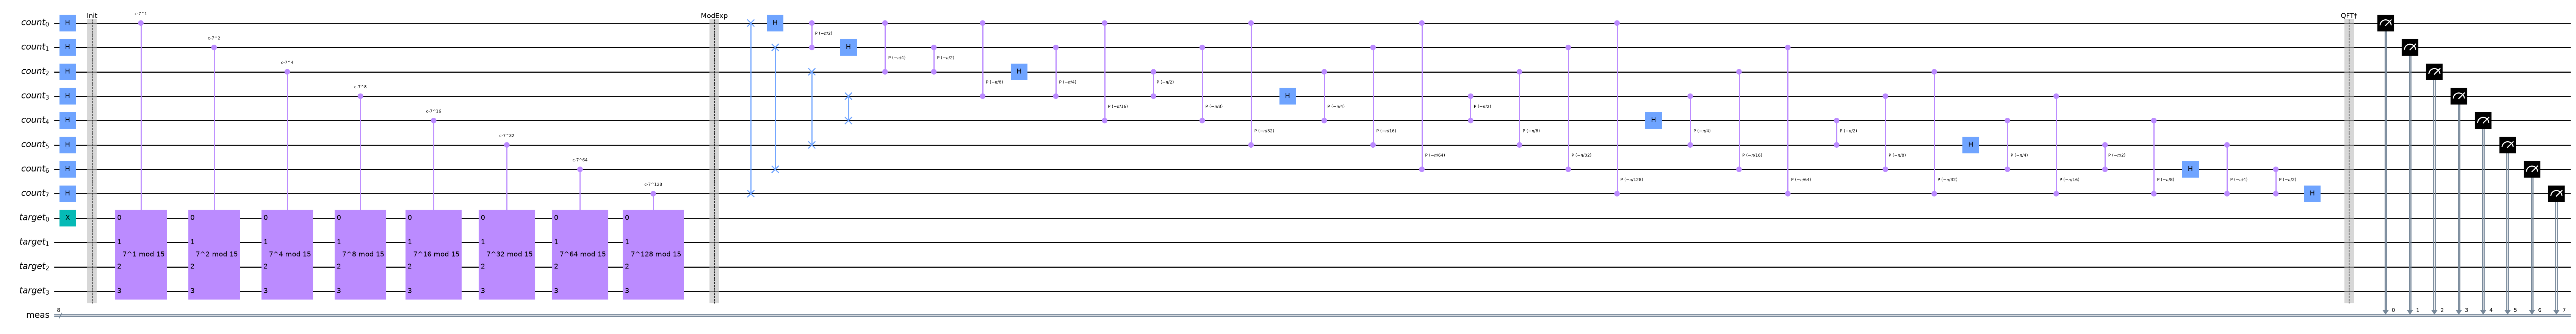

↑ the circuit for a = 7, N = 15: 8 counting + 4 target qubits, one controlled unitary per counting qubit, then QFT† and the measurements

Running the simulation...


transpiled for Aer: 1341 gates, depth 967, 416 CNOTs (the swap-based multiplier of notebook 20 needs ≈ 3 400 gates for N = 15; IQM Resonance would refuse anything above 10 000 native instructions)
══════════════════════════════════════════════════════════════════════
SHOR RESULTS ANALYSIS for a=7, N=15
══════════════════════════════════════════════════════════════════════

True period (classical): r = 4

Outcome      Decimal    Phase        Period     Counts    
------------------------------------------------------------
00000000     0          0.0000       -          1041      
10000000     128        0.5000       2          1035      
11000000     192        0.7500       4          1026      
01000000     64         0.2500       4          994       

────────────────────────────────────────────────────────────
Periods found (sorted by frequency):
  r = 4: 2020 counts (valid) ✓
  r = 2: 1035 counts (invalid) 

────────────────────────────────────────────────────────────
Factorisatio

In [6]:
# ═══════════════════════════════════════════════════════════════
# EXAMPLE 1: Factor 15 with a=7 (the classic case)
# ═══════════════════════════════════════════════════════════════

print("\n" + "▓"*70)
print("EXAMPLE 1: N = 15, a = 7")
print("▓"*70)

result_15 = run_shor_general(N=15, a=7, n_count=8, shots=4096)   # 12 qubits; returns the dict with counts + analysis


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `run_shor_general(N=15, a=7, n_count=8, shots=4096)` | the whole pipeline on the smallest instance: the four ideal peaks m = 0, 64, 128, 192 (≈ 1024 shots each) give φ = 0, ¼, ½, ¾ |
| the `Period` column | `limit_denominator(15)` turns ¼ and ¾ into r = 4 and ½ into r = 2 — the divisor case, `(invalid)` because 7² = 49 ≡ 4 ≠ 1; this version does not try 2r |
| `Factors found! 5 × 3 = 15` | r = 4 → x = 7² mod 15 = 4 → gcd(5, 15) = 5, gcd(3, 15) = 3 |

</details>


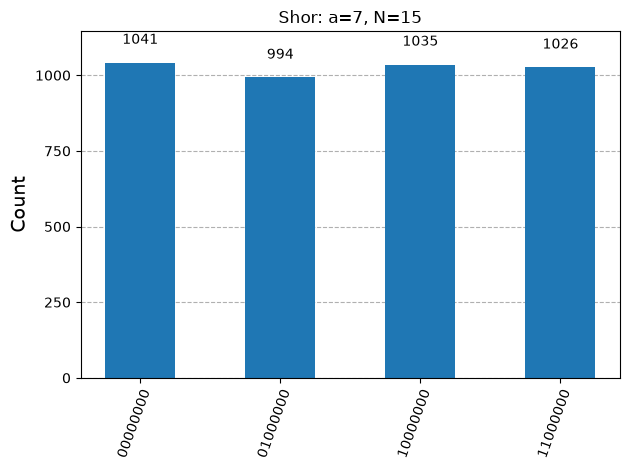

↑ counting-register outcomes for a = 7, N = 15 (256 possible values): ideally four equal peaks at 0, 64, 128, 192 = 256·s/4


In [7]:
# Show the histogram
if result_15 and result_15.get('counts'):                        # .get(): None if the run was skipped (IQM cap) — then there is nothing to plot
    display(plot_histogram(result_15['counts'], title='Shor: a=7, N=15'))
    print("↑ counting-register outcomes for a = 7, N = 15 (256 possible values): ideally four equal peaks at 0, 64, 128, 192 = 256·s/4")
else:
    print("no counts to plot (run skipped)")


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `result.get('counts')` | a guard that works in both editions: the IQM `run_shor_general` returns `counts = None` when the circuit exceeds the cap |
| `display(plot_histogram(...)); print("↑ ...")` | show the figure, then its caption (the figure is no longer the last expression of the cell) |

</details>



▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓
EXAMPLE 2: N = 21, a = 2
▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓

════════════════════════════════════════════════════════════
GENERALIZED SHOR ALGORITHM
════════════════════════════════════════════════════════════
Goal: factor N = 21
Base: a = 2
Shor circuit configuration:
  N = 21, a = 2
  Counting qubits: 10
  Target qubits: 5
  Total qubits: 15


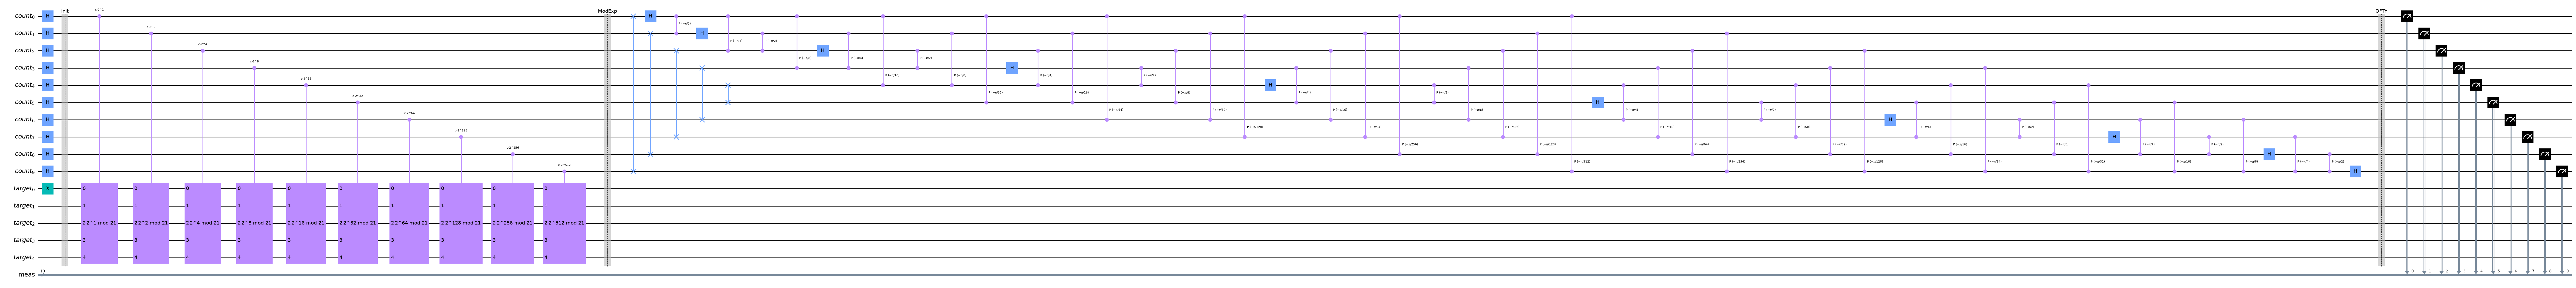

↑ the circuit for a = 2, N = 21: 10 counting + 5 target qubits, one controlled unitary per counting qubit, then QFT† and the measurements

Running the simulation...


transpiled for Aer: 27338 gates, depth 20487, 8640 CNOTs (the swap-based multiplier of notebook 20 needs ≈ 3 400 gates for N = 15; IQM Resonance would refuse anything above 10 000 native instructions)


══════════════════════════════════════════════════════════════════════
SHOR RESULTS ANALYSIS for a=2, N=21
══════════════════════════════════════════════════════════════════════

True period (classical): r = 6

Outcome      Decimal    Phase        Period     Counts    
------------------------------------------------------------
0000000000   0          0.0000       -          719       
1000000000   512        0.5000       2          695       
1010101011   683        0.6670       3          479       
0010101011   171        0.1670       6          468       
1101010101   853        0.8330       6          451       
0101010101   341        0.3330       3          446       
1010101010   682        0.6660       3          120       
0101010110   342        0.3340       3          117       
0010101010   170        0.1660       6          110       
1101010110   854        0.8340       6          103       
1101010111   855        0.8350       6          30        
1101010100   852    

In [8]:
# ═══════════════════════════════════════════════════════════════
# EXAMPLE 2: Factor 21 with a=2
# ═══════════════════════════════════════════════════════════════

print("\n" + "▓"*70)
print("EXAMPLE 2: N = 21, a = 2")
print("▓"*70)

result_21 = run_shor_general(N=21, a=2, n_count=10, shots=4096)  # 15 qubits; the order of 2 mod 21 is 6, not a power of 2: the peaks are no longer exact


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `n_count=10` | 2¹⁰ = 1024 ≥ 21² = 441: the precision the continued-fraction theorem asks for; the order of 2 mod 21 is r = 6 |
| the peaks m ≈ 171, 341, 512, 683, 853 | 1024·s/6 is not an integer for s = 1, 2, 4, 5: the probability spreads over the two neighbours (hence counts in the hundreds, not ≈ 680), exactly the QPE spill-over |
| `r = 3 (invalid)`, `r = 2 (invalid)`, `r = 12 (valid)` | s = 2, 4 give the divisor 3, s = 3 gives 2; off-peak readings land on multiples such as 12 (valid but a^(r/2) ≡ 1 → trivial gcds) |
| `r = 6: Factors found! 3 × 7 = 21` | x = 2³ = 8, gcd(9, 21) = 3, gcd(7, 21) = 7 — see the box below |

</details>


<details open><summary><b>📐 Working it out</b></summary>

**Phase → period for N = 21, a = 2.** The order is $r = 6$ ($2^6 = 64 = 3\cdot 21 + 1$), and $n = 10$ counting qubits give $2^n = 1024$. The ideal phases $s/6$ fall between register values:

| $s$ | $1024\,s/6$ | nearest $m$ | $m/1024$ | `limit_denominator(21)` | candidate $r$ |
|---|---|---|---|---|---|
| 1 | 170.67 | 171 | 0.1670 | $1/6$ | 6 ✓ |
| 2 | 341.33 | 341 | 0.3330 | $1/3$ | 3 (divisor) |
| 3 | 512 | 512 | 0.5 | $1/2$ | 2 (divisor) |
| 4 | 682.67 | 683 | 0.6670 | $2/3$ | 3 (divisor) |
| 5 | 853.33 | 853 | 0.8330 | $5/6$ | 6 ✓ |

*Where $1/6$ comes from.* Euclid on $(1024, 171)$: $1024 = 5\cdot 171 + 169$, $171 = 1\cdot 169 + 2$, $169 = 84\cdot 2 + 1$, $2 = 2\cdot 1$, so $171/1024 = [0;\,5,\,1,\,84,\,2]$ with convergents $\tfrac01, \tfrac15, \tfrac16, \tfrac{85}{509}, \dots$ — the last one with denominator $\le 21$ is $\tfrac16$. (For $m = 170$ the expansion is $[0;\,6,\,42,\,4]$, convergents $\tfrac01, \tfrac16, \dots$: the same answer, which is why a 1-unit spill-over does no harm.) For $m = 853$: $1024 = 1\cdot 853 + 171$, then as above: $[0;\,1,\,4,\,1,\,84,\,2]$, convergents $\tfrac01, \tfrac11, \tfrac45, \tfrac56$ ✓.

*The divisors.* $s = 2, 4$ share the factor 2 with $r$: the fraction reduces to thirds and the candidate is $3$; the check $2^3 = 8 \not\equiv 1$ marks it `(invalid)`. Only $s = 1, 5$ — about a third of the shots — give $r = 6$ directly (notebook 20's `find_period_robust` would rescue the others by trying $2r$).

*From the period to the factors.* $r = 6$ is even; $x = 2^{3} \bmod 21 = 8 \ne 20$; hence $\gcd(9, 21) = 3$ and $\gcd(7, 21) = 7$: the cell prints `r = 6: Factors found! 3 × 7 = 21`.

</details>


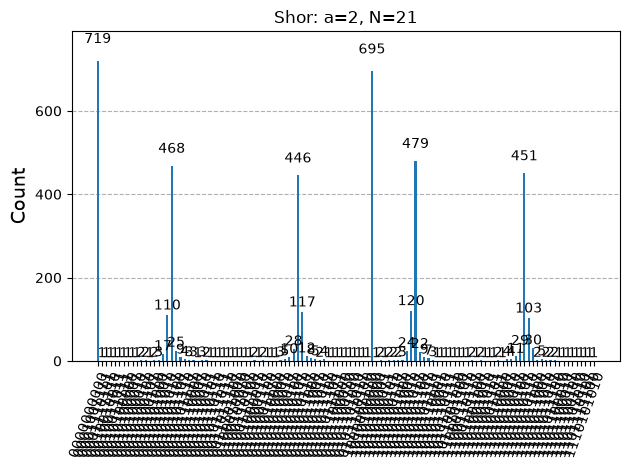

↑ a = 2, N = 21 (1024 possible values): peaks near 0, 171, 341, 512, 683, 853 = 1024·s/6; the non-integer positions spread each peak over two neighbours


In [9]:
if result_21 and result_21.get('counts'):                        # None when the run was skipped (IQM cap)
    display(plot_histogram(result_21['counts'], title='Shor: a=2, N=21'))
    print("↑ a = 2, N = 21 (1024 possible values): peaks near 0, 171, 341, 512, 683, 853 = 1024·s/6; the non-integer positions spread each peak over two neighbours")
else:
    print("no counts to plot (run skipped)")


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `result_21.get('counts')` | the dict returned by `run_shor_general`; `None`/missing when the run was skipped, so the plot is guarded |
| `display(plot_histogram(...))` | the measured register values; the peaks sit near 1024·s/6 because the order of 2 mod 21 is 6 |

</details>



▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓
EXAMPLE 3: N = 35
▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓

════════════════════════════════════════════════════════════
GENERALIZED SHOR ALGORITHM
════════════════════════════════════════════════════════════
Goal: factor N = 35
Base: a = 3
Shor circuit configuration:
  N = 35, a = 3
  Counting qubits: 12
  Target qubits: 6
  Total qubits: 18




↑ the circuit for a = 3, N = 35: 12 counting + 6 target qubits, one controlled unitary per counting qubit, then QFT† and the measurements

Running the simulation...


transpiled for Aer: 134057 gates, depth 101257, 42240 CNOTs (the swap-based multiplier of notebook 20 needs ≈ 3 400 gates for N = 15; IQM Resonance would refuse anything above 10 000 native instructions)


══════════════════════════════════════════════════════════════════════
SHOR RESULTS ANALYSIS for a=3, N=35
══════════════════════════════════════════════════════════════════════

True period (classical): r = 12

Outcome      Decimal    Phase        Period     Counts    
------------------------------------------------------------
000000000000 0          0.0000       -          353       
110000000000 3072       0.7500       4          341       
100000000000 2048       0.5000       2          338       
010000000000 1024       0.2500       4          333       
001010101011 683        0.1667       6          250       
010101010101 1365       0.3333       3          247       
101010101011 2731       0.6667       3          246       
100101010101 2389       0.5833       12         240       
011010101011 1707       0.4167       12         234       
110101010101 3413       0.8333       6          230       
111010101011 3755       0.9167       12         225       
000101010101 341   

In [10]:
# ═══════════════════════════════════════════════════════════════
# EXAMPLE 3: Factor 35 = 5 × 7
# ═══════════════════════════════════════════════════════════════

print("\n" + "▓"*70)
print("EXAMPLE 3: N = 35")
print("▓"*70)

result_35 = run_shor_general(N=35, a=3, n_count=12, shots=4096)  # 18 qubits; the order of 3 mod 35 is 12


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `N=35, a=3, n_count=12` | 6 target + 12 counting qubits = 18; 2¹² = 4096 ≥ 35² = 1225; the order of 3 mod 35 is r = 12, so the phases are s/12 and the useful ones are those with gcd(s, 12) = 1 (s = 1, 5, 7, 11: a third of the shots) |
| ≈ 134 000 transpiled gates | twelve controlled 7-qubit generic unitaries: the synthesis cost grows like 4ⁿ with the target size — Aer still simulates it in about a minute |
| `r = 12: Factors found! 5 × 7 = 35` (or 7 × 5) | x = 3⁶ mod 35 = 729 − 700 = 29; gcd(30, 35) = 5, gcd(28, 35) = 7 |

</details>


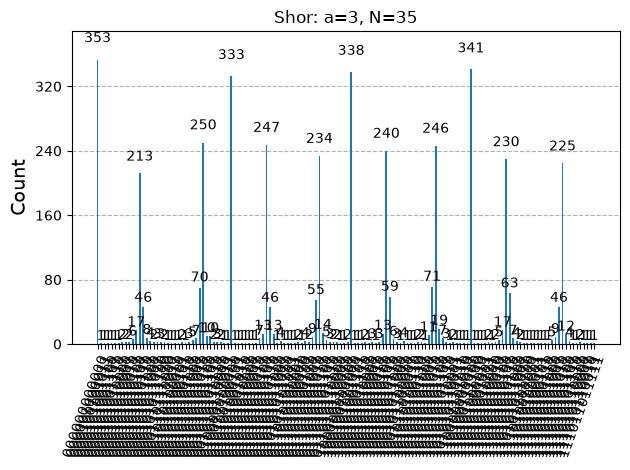

↑ a = 3, N = 35 (4096 possible values): peaks near 4096·s/12; only s coprime to 12 lead straight to r = 12


In [11]:
if result_35 and result_35.get('counts'):                        # None when the run was skipped (IQM cap)
    display(plot_histogram(result_35['counts'], title='Shor: a=3, N=35'))
    print("↑ a = 3, N = 35 (4096 possible values): peaks near 4096·s/12; only s coprime to 12 lead straight to r = 12")
else:
    print("no counts to plot (run skipped)")


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `result_35.get('counts')` | same guard as for N = 21 |
| `plot_histogram` | peaks near 4096·s/12; only s coprime to 12 give r = 12 directly, the others give divisors of 12 |

</details>



▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓
EXAMPLE 4: N = 33, automatic base
▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓
Base chosen automatically: a = 20

════════════════════════════════════════════════════════════
GENERALIZED SHOR ALGORITHM
════════════════════════════════════════════════════════════
Goal: factor N = 33
Base: a = 20
Shor circuit configuration:
  N = 33, a = 20
  Counting qubits: 12
  Target qubits: 6
  Total qubits: 18




↑ the circuit for a = 20, N = 33: 12 counting + 6 target qubits, one controlled unitary per counting qubit, then QFT† and the measurements

Running the simulation...


transpiled for Aer: 134159 gates, depth 101361, 42240 CNOTs (the swap-based multiplier of notebook 20 needs ≈ 3 400 gates for N = 15; IQM Resonance would refuse anything above 10 000 native instructions)


══════════════════════════════════════════════════════════════════════
SHOR RESULTS ANALYSIS for a=20, N=33
══════════════════════════════════════════════════════════════════════

True period (classical): r = 10

Outcome      Decimal    Phase        Period     Counts    
------------------------------------------------------------
100000000000 2048       0.5000       2          418       
000000000000 0          0.0000       -          385       
101100110011 2867       0.7000       10         351       
001100110011 819        0.2000       5          349       
010011001101 1229       0.3000       10         337       
110011001101 3277       0.8000       5          332       
011001100110 1638       0.3999       5          251       
000110011010 410        0.1001       10         238       
111001100110 3686       0.8999       10         237       
100110011010 2458       0.6001       5          230       
011001100111 1639       0.4001       5          111       
111001100111 3687 

In [12]:
# ═══════════════════════════════════════════════════════════════
# EXAMPLE 4: Automatic choice of the base
# ═══════════════════════════════════════════════════════════════

print("\n" + "▓"*70)
print("EXAMPLE 4: N = 33, automatic base")
print("▓"*70)

result_33 = run_shor_general(N=33, n_count=12, shots=4096)  # a chosen automatically (random: the outcome changes from run to run)


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `a=None` → `random.choice(candidates)` | the base is drawn at random among the 20 numbers coprime to 33; its order divides lcm(2, 10) = 10, so r ∈ {1, 2, 5, 10} |
| success or `⚠ No factor found` | an odd order (5) or a^(r/2) ≡ −1 (e.g. a = 32 = −1, order 2) fails: this is the probabilistic nature of Shor — rerun the cell, or use `try_multiple_bases` below |

</details>


## Helper Function to Try Different Bases

In [13]:
def try_multiple_bases(N: int, max_attempts: int = 5, shots: int = 2048) -> dict:
    """
    Try different bases until the factors are found.
    
    Args:
        N: Number to factor
        max_attempts: Maximum number of attempts
        shots: Shots for each attempt
    
    Returns:
        Result of the factorisation
    """
    import random
    
    print(f"Attempting to factor N = {N}")
    print(f"Available coprime bases: ", end="")            # end="" keeps the list on the same line
    coprimes = [x for x in range(2, min(N, 20)) if gcd(x, N) == 1]   # candidate bases below 20
    print(coprimes[:10], "..." if len(coprimes) > 10 else "")
    print()
    
    for attempt in range(max_attempts):
        # Choose a base
        a = random.choice(coprimes)
        print(f"\n--- Attempt {attempt + 1}: a = {a} ---")
        
        result = run_shor_general(N, a=a, shots=shots, verbose=False)   # verbose=False: no drawing, no configuration printout
        
        if result and (result.get('analysis') or {}).get('factors'):   # `or {}` : analysis is None when the run was skipped
            f1, f2 = result['analysis']['factors']
            if f1:
                print(f"\n✓ SUCCESS! Factors found: {f1} × {N//f1 if f2 is None else f2} = {N}")
                return result                                # leave the function at the first success
        
        print(f"  No factor found with a={a}")
    
    print(f"\n✗ No factor found after {max_attempts} attempts")
    return None

# Test
print("="*70)
print("TEST: Factorisation with multiple bases")
print("="*70)
result = try_multiple_bases(55, max_attempts=3, shots=2048)   # 55 = 5 × 11: 6 target + 12 counting qubits


TEST: Factorisation with multiple bases
Attempting to factor N = 55
Available coprime bases: [2, 3, 4, 6, 7, 8, 9, 12, 13, 14] ...


--- Attempt 1: a = 14 ---
Shor circuit configuration:
  N = 55, a = 14
  Counting qubits: 12
  Target qubits: 6
  Total qubits: 18


══════════════════════════════════════════════════════════════════════
SHOR RESULTS ANALYSIS for a=14, N=55
══════════════════════════════════════════════════════════════════════

True period (classical): r = 10

Outcome      Decimal    Phase        Period     Counts    
------------------------------------------------------------
000000000000 0          0.0000       -          194       
100000000000 2048       0.5000       2          190       
001100110011 819        0.2000       5          186       
010011001101 1229       0.3000       10         184       
101100110011 2867       0.7000       10         172       
110011001101 3277       0.8000       5          169       
000110011010 410        0.1001       10         143       
111001100110 3686       0.8999       10         132       
011001100110 1638       0.3999       5          129       
100110011010 2458       0.6001       5          123       
100110011001 2457       0.5999       5          57        
000110011001 409  

<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `for attempt in range(max_attempts)` + `random.choice(coprimes)` | the outer classical loop of Shor's algorithm: a fresh random base per attempt until the post-processing yields a factor |
| `(result.get('analysis') or {}).get('factors')` | safe navigation through the result dict: `or {}` replaces a missing/None analysis by an empty dict so that `.get` never fails |
| `verbose=False` | the per-attempt output is reduced to the analysis table (the builder's configuration lines are still printed by `build_shor_circuit_general`) |
| `N//f1 if f2 is None else f2` | `find_factors` may return only one non-trivial gcd; the cofactor is then N / f1 |

</details>


## 🔬 In-depth analysis

These three tasks need no backend (NumPy and the exact statevector), so they run identically in the IBM and the IQM edition.

1. **Eigenvalues of the permutation matrix.** For $(a, N) = (7, 15), (2, 21), (3, 35)$ read the cycle structure of `modular_multiplication_matrix(a, N)` (follow $x \to ax \bmod N$ until it returns) and show that the order $r$ is the lcm of the cycle lengths. Then compute the eigenvalues with `np.linalg.eigvals` and verify that every eigenphase is a multiple of $1/r$ — the $e^{2\pi i s/r}$ of the theory section.
2. **The cost of a generic unitary.** Transpile a single `create_controlled_modmul_gate(a, 0, N)` for the three cases into the universal basis `['cx', 'u']` (`generate_preset_pass_manager(optimization_level=1, basis_gates=[...])`) and count the CNOTs. How does the count grow with the number of target qubits? Compare with the 7-gate swap multiplier of notebook 20 and with the 10 000-instruction cap of IQM Resonance.
3. **Precision for $N = 21$, exactly.** Build the circuit for $a = 2$, $N = 21$ with `n_count` = 6, 8, 10, drop the measurements, and take the exact distribution of the counting register from `Statevector(...).probabilities(qargs=...)`. With `extract_period_from_phase`, compute the probability that a shot yields $r = 6$ directly, and the probability that it yields a divisor (2 or 3). Which `n_count` is enough, and why does $2^n \ge N^2$ matter here while it did not for $N = 15$?

Write your code in the empty cell below; a reference solution follows it. Try first, then compare.


In [14]:
# 🔬 In-depth analysis — your code here



In [15]:
# Reference solution
from collections import Counter                                                   # a counting dict
from math import lcm                                                              # least common multiple (Python ≥ 3.9)
from qiskit.quantum_info import Statevector                                       # exact simulation of a circuit without measurements
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager   # (already imported in the IBM edition; harmless)
import io, contextlib                                                             # to silence the builder's printout

# (1) cycle structure and eigenphases of the permutation matrix
for a_, N_ in ((7, 15), (2, 21), (3, 35)):
    U_ = modular_multiplication_matrix(a_, N_)
    perm = np.argmax(U_, axis=0)                                                  # perm[x] = image of x (row of the 1 in column x)
    seen, lengths = set(), []
    for x0 in range(len(perm)):
        if x0 in seen: continue
        x, L = x0, 0
        while x not in seen: seen.add(x); x = int(perm[x]); L += 1               # follow the arrows until the cycle closes
        lengths.append(L)
    r_ = lcm(*lengths)                                                            # the order is the lcm of all cycle lengths
    phases = np.mod(np.angle(np.linalg.eigvals(U_)) / (2 * np.pi), 1)            # eigenvalue phases in [0, 1)
    multiples = np.allclose(np.round(phases * r_), phases * r_, atol=1e-8)        # every phase = s/r with integer s?
    print(f"(1) a = {a_}, N = {N_}: cycle lengths {dict(sorted(Counter(lengths).items()))} -> lcm = {r_} = order "
          f"(check {pow(a_, r_, N_) == 1}); all {len(U_)} eigenphases are multiples of 1/{r_}: {multiples}")

# (2) CNOT count of one controlled multiplier after synthesis into cx + u
pm_cx = generate_preset_pass_manager(optimization_level=1, basis_gates=['cx', 'u'])
for a_, N_ in ((7, 15), (2, 21), (3, 35)):
    g = create_controlled_modmul_gate(a_, 0, N_)
    qc_ = QuantumCircuit(g.num_qubits); qc_.append(g, range(g.num_qubits))
    ops = pm_cx.run(qc_).count_ops()
    print(f"(2) N = {N_}: one controlled multiplier on {g.num_qubits} qubits -> {ops.get('cx', 0)} CNOT + {ops.get('u', 0)} 1-qubit gates "
          f"(one per counting qubit; notebook 20's swap multiplier for N = 15: 3 cswap + 4 cx)")

# (3) exact distribution of the counting register for N = 21, a = 2 and the phase -> period step
for n_ in (6, 8, 10):
    with contextlib.redirect_stdout(io.StringIO()):                               # the builder prints its configuration: hide it
        qc_ = build_shor_circuit_general(2, 21, n_)
    qc_.remove_final_measurements()                                               # keep the unitary part only (also drops the classical register)
    probs = Statevector(qc_).probabilities(qargs=list(range(n_)))                 # marginal distribution of the counting qubits 0 … n−1
    r_of = [extract_period_from_phase(m_ / 2 ** n_, 21) for m_ in range(2 ** n_)] # the candidate period of every outcome
    p6 = sum(p for m_, p in enumerate(probs) if r_of[m_] == 6)
    pdiv = sum(p for m_, p in enumerate(probs) if r_of[m_] in (2, 3))
    top = sorted(int(m_) for m_ in np.argsort(probs)[::-1][:6])                   # the six most likely outcomes
    print(f"(3) N = 21, n_count = {n_:2d}: P(r = 6) = {p6:.3f}, P(divisor 2 or 3) = {pdiv:.3f}, P(other) = {1 - p6 - pdiv:.3f}; most likely m: {top}")


(1) a = 7, N = 15: cycle lengths {1: 4, 4: 3} -> lcm = 4 = order (check True); all 16 eigenphases are multiples of 1/4: True
(1) a = 2, N = 21: cycle lengths {1: 12, 2: 1, 3: 2, 6: 2} -> lcm = 6 = order (check True); all 32 eigenphases are multiples of 1/6: True
(1) a = 3, N = 35: cycle lengths {1: 30, 4: 1, 6: 1, 12: 2} -> lcm = 12 = order (check True); all 64 eigenphases are multiples of 1/12: True
(2) N = 15: one controlled multiplier on 5 qubits -> 246 CNOT + 402 1-qubit gates (one per counting qubit; notebook 20's swap multiplier for N = 15: 3 cswap + 4 cx)


(2) N = 21: one controlled multiplier on 6 qubits -> 1046 CNOT + 1686 1-qubit gates (one per counting qubit; notebook 20's swap multiplier for N = 15: 3 cswap + 4 cx)


(2) N = 35: one controlled multiplier on 7 qubits -> 4310 CNOT + 6870 1-qubit gates (one per counting qubit; notebook 20's swap multiplier for N = 15: 3 cswap + 4 cx)


(3) N = 21, n_count =  6: P(r = 6) = 0.000, P(divisor 2 or 3) = 0.395, P(other) = 0.605; most likely m: [0, 11, 21, 32, 43, 53]


(3) N = 21, n_count =  8: P(r = 6) = 0.285, P(divisor 2 or 3) = 0.475, P(other) = 0.240; most likely m: [0, 43, 85, 128, 171, 213]


(3) N = 21, n_count = 10: P(r = 6) = 0.322, P(divisor 2 or 3) = 0.494, P(other) = 0.184; most likely m: [0, 171, 341, 512, 683, 853]


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `np.argmax(U_, axis=0)` | the permutation as a list: the row of the 1 in every column |
| `while x not in seen: ... x = int(perm[x])` | walk a cycle until it closes; the lengths are the orbit sizes of x → ax mod N (units: length r; multiples of a prime factor: shorter; 0 and the unused states: 1) |
| `lcm(*lengths)` | the order is the least common multiple of the cycle lengths — and a permutation matrix's eigenvalues are the L-th roots of unity of its L-cycles, hence all phases are multiples of 1/r |
| `np.mod(np.angle(eigvals) / (2π), 1)` | eigenvalue e^{2πiφ} → φ ∈ [0, 1); `np.round(phases * r_)` tests whether r·φ is an integer |
| `basis_gates=['cx', 'u']` | a backend-independent universal basis; the CNOT count of a generic n-qubit unitary grows like 4ⁿ (≈ 100 → 700 → 2 000 … for 5, 6, 7 qubits); IQM's native count is a few times larger after routing |
| `Statevector(qc_).probabilities(qargs=...)` | the exact outcome distribution of the counting register (no shots, no noise); `remove_final_measurements()` is required because a statevector cannot contain measurements |
| `P(r = 6)` vs `n_count` | with 6 counting qubits the nearest register value 11/64 is closer to 3/17 than to 1/6 and `limit_denominator(21)` picks the wrong fraction; from 2ⁿ ≥ N² (n ≥ 9) the convergent is guaranteed — for N = 15, r = 4 divides every 2ⁿ, so the peaks were exact at any n |

</details>


## Limitations and Notes

### Limitations of the Permutation-Matrix Method

1. **Memory**: the matrix has size $2^n \times 2^n$, where $n = \lceil \log_2(N) \rceil$
   - N=15: 16×16 matrix ✓
   - N=63: 64×64 matrix ✓
   - N=127: 128×128 matrix ✓
   - N=255: 256×256 matrix ⚠ (heavy)
   - N>1000: impractical with this method

2. **Circuit depth**: generic unitary gates are decomposed into many elementary gates

### For Large N: Arithmetic Circuits

To factor large numbers (such as RSA-2048), arithmetic circuits are needed:
- **Draper Adder**: addition using the QFT
- **VBE Multiplier**: multiplication with Toffoli gates
- **Beauregard Circuit**: optimised for Shor

These methods use more auxiliary qubits but scale polynomially with $\log(N)$.

---

**Version**: 2.2.0 (Generalized)  
**Notes**: works for N up to ~128 with the permutation-matrix method